# Dataset Cleaning: Trash Detection (COCO)

This notebook fixes the issues found during inspection and produces a clean copy of the dataset in `/content/trash-clean`, which is the folder to use for training. The original download is left untouched in `/content/trash-raw`.

| Issue | Fix | Where |
|---|---|---|
| 1. `trash` class is small | Nothing to change in the data, document it | Section 1 |
| 2. Duplicate `trash` category / phantom class | Remove unused category, remap IDs to 0 to 5 | Section 3 |
| 3. Unlabeled images | Remove them from the JSON and from disk | Section 4 |
| 4. Version and source | Record provenance in `dataset_info.json` | Section 6 |

Run the cells in order. Before running, add your Roboflow key in Colab under the key icon (Secrets) with the name `ROBOFLOW_API_KEY` and turn on notebook access.

## 0. Download the raw dataset and make a working copy

In [ ]:
!pip install -q roboflow

import os, json, shutil, random, datetime
from collections import Counter
from roboflow import Roboflow
from google.colab import userdata

WORKSPACE = "princesss-workspace-2dq44"
PROJECT   = "trash-detection-kcsnu-1kabv"
VERSION   = 1

RAW   = "/content/trash-raw"
CLEAN = "/content/trash-clean"

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
dataset = rf.workspace(WORKSPACE).project(PROJECT).version(VERSION).download("coco", location=RAW)

SPLITS = [s for s in ["train", "valid", "test"] if os.path.exists(f"{RAW}/{s}/_annotations.coco.json")]
print("Splits:", SPLITS)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 1.3 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/trash-raw in coco:: 100%|██████████| 2528/2528 [00:00<00:00, 6860.02it/s]

Splits: ['train', 'valid', 'test']


In [ ]:
# Fresh working copy: all edits below happen in CLEAN only
if os.path.exists(CLEAN):
    shutil.rmtree(CLEAN)
shutil.copytree(RAW, CLEAN)

def load(split):
    with open(f"{CLEAN}/{split}/_annotations.coco.json") as f:
        return json.load(f)

def save(split, data):
    with open(f"{CLEAN}/{split}/_annotations.coco.json", "w") as f:
        json.dump(data, f)

coco = {s: load(s) for s in SPLITS}
print({s: (len(coco[s]["images"]), len(coco[s]["annotations"])) for s in SPLITS}, "(images, boxes) before cleaning")

{'train': (1767, 1773), 'valid': (379, 383), 'test': (378, 382)} (images, boxes) before cleaning


## 1. Small `trash` class (no data change)

The `trash` class has only about 139 boxes, with very few in the test split. This is not something to fix by editing the data. In the report, state the per-class counts next to the per-class precision, recall, and AP, and note that the `trash` numbers are less reliable because of the small test sample. Do not over-interpret differences of a few points for that class.

## 2. Check which category IDs actually have boxes

Roboflow's COCO export often includes a placeholder category with ID 0 that has no boxes. Here the category list shows `trash` twice (IDs 0 and 6), so first confirm which IDs are really used.

In [ ]:
ref_cats = coco[SPLITS[0]]["categories"]
print("Categories in file:", [(c["id"], c["name"]) for c in ref_cats])

box_counts = Counter(a["category_id"] for s in SPLITS for a in coco[s]["annotations"])
print("Boxes per original category ID:", dict(sorted(box_counts.items())))
print("IDs with zero boxes:", [c["id"] for c in ref_cats if box_counts.get(c["id"], 0) == 0])

Categories in file: [(0, 'trash'), (1, 'cardboard'), (2, 'glass'), (3, 'metal'), (4, 'paper'), (5, 'plastic'), (6, 'trash')]
Boxes per original category ID: {1: 407, 2: 501, 3: 415, 4: 594, 5: 482, 6: 139}
IDs with zero boxes: [0]


## 3. Remove the phantom category and remap IDs to 0 to 5

Only categories that have boxes are kept. If two used IDs share a name, they are merged into one class. The classes are renumbered contiguously (0 to 5), so the class count is exactly 6 whether a library counts `len(categories)` or `max(id) + 1`.

In [ ]:
used_ids = set(box_counts)

names = []
for c in sorted(ref_cats, key=lambda c: c["id"]):
    if c["id"] in used_ids and c["name"] not in names:
        names.append(c["name"])

name_to_new = {n: i for i, n in enumerate(names)}
id_map = {c["id"]: name_to_new[c["name"]] for c in ref_cats if c["id"] in used_ids}
new_cats = [{"id": i, "name": n, "supercategory": "none"} for i, n in enumerate(names)]

for s in SPLITS:
    for a in coco[s]["annotations"]:
        a["category_id"] = id_map[a["category_id"]]
    coco[s]["categories"] = new_cats
    save(s, coco[s])

print("Old -> new ID map:", id_map)
print("New categories   :", [(c["id"], c["name"]) for c in new_cats])

Old -> new ID map: {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5}
New categories   : [(0, 'cardboard'), (1, 'glass'), (2, 'metal'), (3, 'paper'), (4, 'plastic'), (5, 'trash')]


## 4. Remove images that have no boxes

Images without annotations are deleted from both the JSON and the disk (in the clean copy only).

In [ ]:
removed = {}
for s in SPLITS:
    labeled = {a["image_id"] for a in coco[s]["annotations"]}
    empty = [im for im in coco[s]["images"] if im["id"] not in labeled]
    for im in empty:
        p = f"{CLEAN}/{s}/{im['file_name']}"
        if os.path.exists(p):
            os.remove(p)
    coco[s]["images"] = [im for im in coco[s]["images"] if im["id"] in labeled]
    save(s, coco[s])
    removed[s] = [im["file_name"] for im in empty]

for s, files in removed.items():
    print(f"{s}: removed {len(files)} image(s) {files}")

train: removed 4 image(s) ['metal363_jpg.rf.8025a815be2a6b69d9a3fe8af9083be3.jpg', 'glass225_jpg.rf.14b297b2b2fe9e21b62c6f07e3b86522.jpg', 'metal136_jpg.rf.9343a24d8b2e15d54ce2879c9c79a301.jpg', 'metal140_jpg.rf.5cfac5fe21e77b572772636a224d1806.jpg']
valid: removed 0 image(s) []
test: removed 1 image(s) ['metal13_jpg.rf.225a7dff84520039db304223730b2c2a.jpg']


## 5. Verify the cleaned dataset

Re-reads the files from disk and checks that IDs are contiguous, every box points to a valid class, every image has at least one box, and every image file exists. Then it compares each box label with the class prefix in the filename (for example `paper509_...` should be labeled `paper`). That second check only works because this dataset's filenames start with the class name, and it also catches mislabeled images.

In [ ]:
final = {s: load(s) for s in SPLITS}

for s in SPLITS:
    d = final[s]
    ids = [c["id"] for c in d["categories"]]
    assert ids == list(range(len(ids))), "Category IDs are not contiguous"
    assert all(a["category_id"] in ids for a in d["annotations"]), "Box with invalid class"
    labeled = {a["image_id"] for a in d["annotations"]}
    assert all(im["id"] in labeled for im in d["images"]), "Image without boxes remains"
    assert all(os.path.exists(f"{CLEAN}/{s}/{im['file_name']}") for im in d["images"]), "Missing image file"
    cnt = Counter(a["category_id"] for a in d["annotations"])
    print(f"{s:>5}: {len(d['images'])} images, {len(d['annotations'])} boxes", {names[k]: v for k, v in sorted(cnt.items())})

print("\nAll structural checks passed. Number of classes:", len(names), names)

# Filename-prefix vs label check
mismatch = []
for s in SPLITS:
    fname = {im["id"]: im["file_name"] for im in final[s]["images"]}
    for a in final[s]["annotations"]:
        label = names[a["category_id"]]
        if not fname[a["image_id"]].lower().startswith(label):
            mismatch.append((s, fname[a["image_id"]], label))
print(f"\nBoxes whose label does not match the filename prefix: {len(mismatch)}")
for m in mismatch[:10]:
    print("  ", m)

train: 1763 images, 1773 boxes {'cardboard': 284, 'glass': 347, 'metal': 300, 'paper': 435, 'plastic': 313, 'trash': 94}
valid: 379 images, 383 boxes {'cardboard': 68, 'glass': 65, 'metal': 61, 'paper': 73, 'plastic': 86, 'trash': 30}
 test: 377 images, 382 boxes {'cardboard': 55, 'glass': 89, 'metal': 54, 'paper': 86, 'plastic': 83, 'trash': 15}

All structural checks passed. Number of classes: 6 ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

Boxes whose label does not match the filename prefix: 5
   ('train', 'metal405_jpg.rf.1b7ded929da646045b736b750ac57dc2.jpg', 'glass')
   ('train', 'glass186_jpg.rf.6f76bd6125432a5e01e84b0391c3a2b7.jpg', 'metal')
   ('train', 'glass170_jpg.rf.0b1f15b11008391b6421142f949865b5.jpg', 'metal')
   ('test', 'glass55_jpg.rf.8ba24f8d340244a4a06cbdf177e3a19e.jpg', 'cardboard')
   ('test', 'glass122_jpg.rf.23fa057e33da4bdf4fac6f6753490290.jpg', 'cardboard')


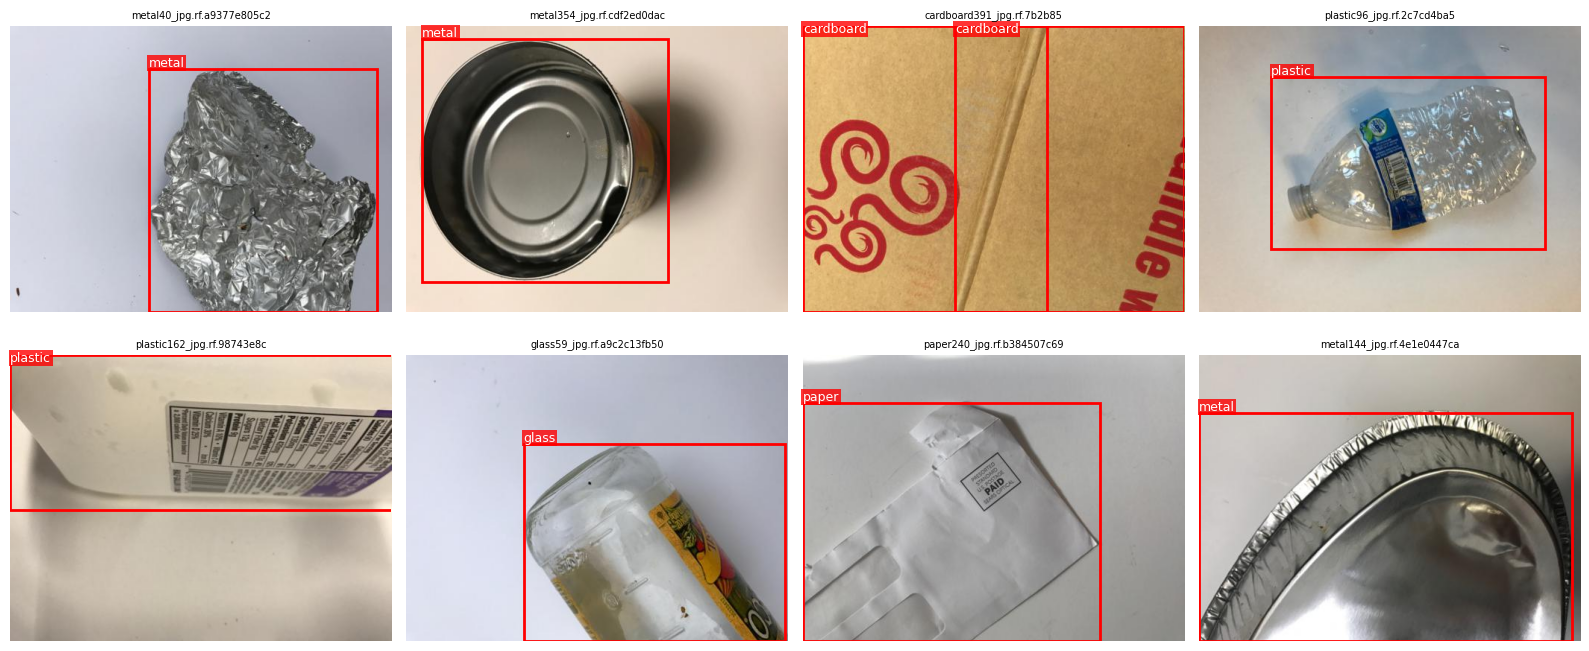

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

def show(split="train", n=8, seed=0):
    d = final[split]
    by_img = {}
    for a in d["annotations"]:
        by_img.setdefault(a["image_id"], []).append(a)
    ims = random.Random(seed).sample(d["images"], n)
    cols = n // 2
    fig, axes = plt.subplots(2, cols, figsize=(4 * cols, 7))
    for ax, im in zip(axes.ravel(), ims):
        ax.imshow(Image.open(f"{CLEAN}/{split}/{im['file_name']}").convert("RGB"))
        ax.axis("off")
        for a in by_img[im["id"]]:
            x, y, w, h = a["bbox"]
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=2))
            ax.text(x, max(y - 3, 8), names[a["category_id"]], color="white", fontsize=9,
                    bbox=dict(facecolor="red", alpha=0.8, pad=1, edgecolor="none"))
        ax.set_title(im["file_name"][:26], fontsize=7)
    plt.tight_layout()
    plt.show()

show("train", n=8, seed=0)

## 6. Record provenance for the report and README

Saves a small `dataset_info.json` next to the data and prints it, so the source, version, access date, cleaning steps, and final counts are written down in one place.

In [ ]:
info = {
    "source": "Roboflow Universe",
    "workspace": WORKSPACE,
    "project": PROJECT,
    "version": VERSION,
    "export_format": "COCO",
    "downloaded_on": str(datetime.date.today()),
    "cleaning_steps": [
        "Removed unused placeholder category and remapped class IDs to 0-5",
        "Removed images with no annotations",
    ],
    "classes": names,
    "images_per_split": {s: len(final[s]["images"]) for s in SPLITS},
    "boxes_per_split": {s: len(final[s]["annotations"]) for s in SPLITS},
    "removed_unlabeled_images": removed,
}
with open(f"{CLEAN}/dataset_info.json", "w") as f:
    json.dump(info, f, indent=2)
print(json.dumps(info, indent=2))

{
  "source": "Roboflow Universe",
  "workspace": "princesss-workspace-2dq44",
  "project": "trash-detection-kcsnu-1kabv",
  "version": 1,
  "export_format": "COCO",
  "downloaded_on": "2026-10-14",
  "cleaning_steps": [
    "Removed unused placeholder category and remapped class IDs to 0-5",
    "Removed images with no annotations"
  ],
  "classes": [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
  ],
  "images_per_split": {
    "train": 1763,
    "valid": 379,
    "test": 377
  },
  "boxes_per_split": {
    "train": 1773,
    "valid": 383,
    "test": 382
  },
  "removed_unlabeled_images": {
    "train": [
      "metal363_jpg.rf.8025a815be2a6b69d9a3fe8af9083be3.jpg",
      "glass225_jpg.rf.14b297b2b2fe9e21b62c6f07e3b86522.jpg",
      "metal136_jpg.rf.9343a24d8b2e15d54ce2879c9c79a301.jpg",
      "metal140_jpg.rf.5cfac5fe21e77b572772636a224d1806.jpg"
    ],
    "valid": [],
    "test": [
      "metal13_jpg.rf.225a7dff84520039db304223730b2c2a.jpg"
  

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os, shutil
PROJECT_DIR = "/content/drive/MyDrive/rf-detr-trash"
os.makedirs(PROJECT_DIR, exist_ok=True)

shutil.make_archive(f"{PROJECT_DIR}/trash-clean", "zip", root_dir="/content", base_dir="trash-clean")
print("Saved cleaned dataset to", f"{PROJECT_DIR}/trash-clean.zip")

Mounted at /content/drive
Saved cleaned dataset to /content/drive/MyDrive/rf-detr-trash/trash-clean.zip


The cleaned dataset is now in `/content/trash-clean` (folders `train/`, `valid/`, `test/`, each with `_annotations.coco.json`). Use this folder for training. Colab storage is wiped when the runtime resets, but re-running this notebook rebuilds it in under a minute.